# 01 · EDA and training
Exploration of the banking-transactions dataset and the minimal training pipeline used by Tasks 9-10. All model code lives in `src/`; this notebook inspects the data and re-uses the saved artifacts.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config as C
df = pd.read_csv(C.CLEAN_CSV, parse_dates=[C.DATE_COL])
print(df.shape); df.head()

(5389, 21)


,Transaction_ID,Account_Number,Transaction_Date,Transaction_Amount,Merchant_Name,Transaction_Type,Category,City,Country,Payment_Method,...,Customer_Gender,Customer_Occupation,Customer_Income,Account_Balance,Transaction_Status,Fraud_Flag,Discount_Applied,Loyalty_Points_Earned,Transaction_Description,is_fraud
0,bdd640fb-0667-4ad1-9c80-317fa3b1799d,IUPM04409079772781,2023-11-05 15:54:38,3198.94,Houston Group,Debit,Transport,Phoenix,USA,Online Transfer,...,Others,Quality manager,80466.03,350.28,Failed,No,True,304,Recently company detail form range a.,0
1,23b8c1e9-3924-46de-beb1-3b9046685257,BLAT22216107051843,2024-04-21 22:21:55,129.93,Anderson-Phillips,Credit,Grocery,Philadelphia,USA,Debit Card,...,Others,Civil Service fast streamer,145574.25,9797.81,Pending,Yes,False,383,Anything son baby power heart will not up.,1
2,bd9c66b3-ad3c-4d6d-9a3d-1fa7bc8960a9,UTXA55295806601382,2023-07-17 13:25:56,1378.77,Jensen Group,Credit,Shopping,New York,USA,Debit Card,...,Others,"Pilot, airline",33447.18,12399.85,Failed,Yes,False,497,Form world around green bar environment pattern.,1
3,972a8469-1641-4f82-8b9d-2434e465e150,XICF70493862044851,2023-06-27 16:09:52,1119.94,"Nelson, Gomez and Rodriguez",Credit,Healthcare,Dallas,USA,Online Transfer,...,Male,"Radiographer, therapeutic",108801.45,16057.64,Failed,Yes,True,495,Order evening source these opportunity trade i...,1
4,17fc695a-07a0-4a6e-8822-e8f36c031199,KOSW19711121259020,2024-03-26 23:45:31,3683.67,Caldwell Group,Credit,Entertainment,San Jose,USA,E-Wallet,...,Others,Diplomatic Services operational officer,100985.12,14940.54,Failed,Yes,True,292,Exactly politics door suggest.,1


In [2]:
print(df.dtypes); print('missing values:', int(df.isna().sum().sum()))
print('fraud rate:', round(df[C.TARGET].mean(), 4), '| date range:', df[C.DATE_COL].min(), '->', df[C.DATE_COL].max())

Transaction_ID                     object
Account_Number                     object
Transaction_Date           datetime64[ns]
Transaction_Amount                float64
Merchant_Name                      object
Transaction_Type                   object
Category                           object
City                               object
Country                            object
Payment_Method                     object
Customer_Age                        int64
Customer_Gender                    object
Customer_Occupation                object
Customer_Income                   float64
Account_Balance                   float64
Transaction_Status                 object
Fraud_Flag                         object
Discount_Applied                     bool
Loyalty_Points_Earned               int64
Transaction_Description            object
is_fraud                            int64
dtype: object
missing values: 0
fraud rate: 0.493 | date range: 2023-01-21 08:42:42 -> 2025-01-20 12:21:18


## Does any feature separate fraud from legitimate transactions?

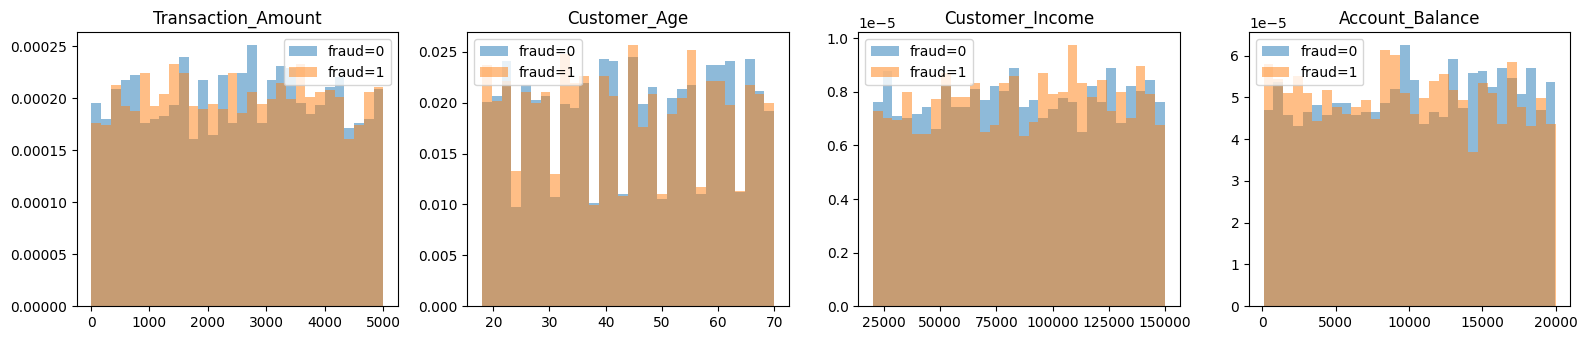

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axs, C.NUMERIC_INPUTS):
    for lab, d in df.groupby(C.TARGET): ax.hist(d[col], bins=30, alpha=.5, density=True, label=f'fraud={lab}')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

In [4]:
for col in ['Category', 'Payment_Method', 'Transaction_Type', 'Customer_Gender', 'Transaction_Status']:
    print(df.groupby(col)[C.TARGET].mean().round(3).to_dict())

{'Clothing': 0.482, 'Education': 0.478, 'Electronics': 0.479, 'Entertainment': 0.493, 'Fitness': 0.527, 'Food': 0.47, 'Grocery': 0.527, 'Healthcare': 0.505, 'Housing': 0.49, 'Savings': 0.462, 'Shopping': 0.505, 'Transport': 0.499, 'Travel': 0.45, 'Utilities': 0.535}
{'Cash': 0.5, 'Credit Card': 0.503, 'Debit Card': 0.5, 'E-Wallet': 0.483, 'Online Transfer': 0.481}
{'Credit': 0.495, 'Debit': 0.491}
{'Female': 0.486, 'Male': 0.496, 'Others': 0.497}
{'Failed': 0.492, 'Pending': 0.492, 'Success': 0.495}


Fraud rate is ~49% in every group and the distributions overlap almost entirely, which already suggests there is little learnable signal.

In [5]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
X = df[C.NUMERIC_INPUTS + ['Loyalty_Points_Earned']].copy(); X['hour'] = df[C.DATE_COL].dt.hour; X['dow'] = df[C.DATE_COL].dt.dayofweek
auc = cross_val_score(GradientBoostingClassifier(random_state=C.SEED), X, df[C.TARGET], cv=5, scoring='roc_auc')
print('5-fold gradient boosting ROC-AUC:', auc.round(3), 'mean', auc.mean().round(3))

5-fold gradient boosting ROC-AUC: [0.503 0.516 0.511 0.513 0.506] mean 0.51


## Trained models (from `python -m src.train`)

In [6]:
meta = json.load(open(C.METADATA_PATH)); m = json.load(open(C.REPORTS_DIR / 'metrics.json'))
print({k: meta[k] for k in ['dataset_rows', 'split_sizes', 'threshold', 'threshold_f1_unconstrained', 'threshold_cost_optimal', 'epochs_run', 'trained_at']})
pd.DataFrame({'DNN': m['dnn'], 'LR': m['lr']}).drop('confusion_matrix').round(4)

{'dataset_rows': 5389, 'split_sizes': {'train': 3772, 'val': 808, 'test': 809}, 'threshold': 0.5, 'threshold_f1_unconstrained': 0.01, 'threshold_cost_optimal': 0.01, 'epochs_run': 34, 'trained_at': '2026-10-12T04:42:36+00:00'}


,DNN,LR
threshold,0.5,0.5
roc_auc,0.523516,0.510123
pr_auc,0.508312,0.506162
f1,0.376396,0.458564
precision,0.517544,0.510769
recall,0.295739,0.41604
accuracy,0.516687,0.515451
flag_rate,0.281829,0.401731


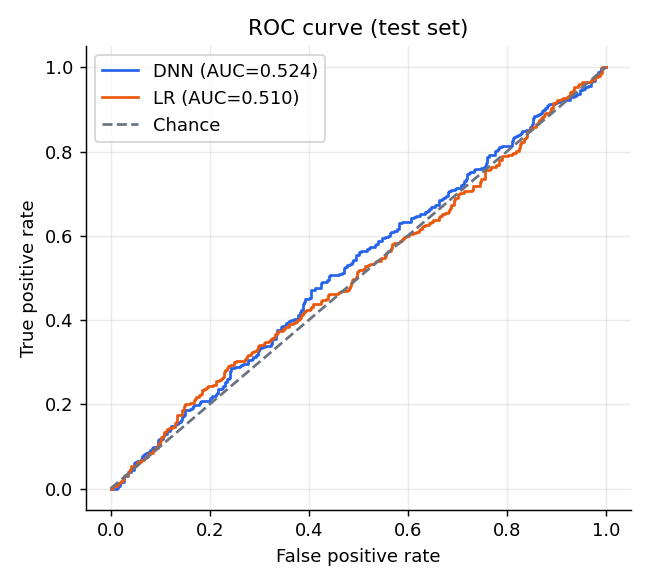

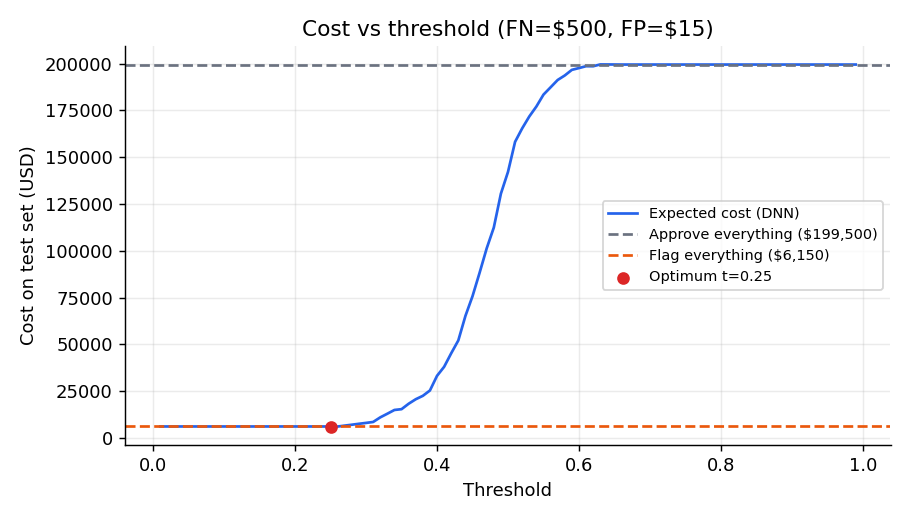

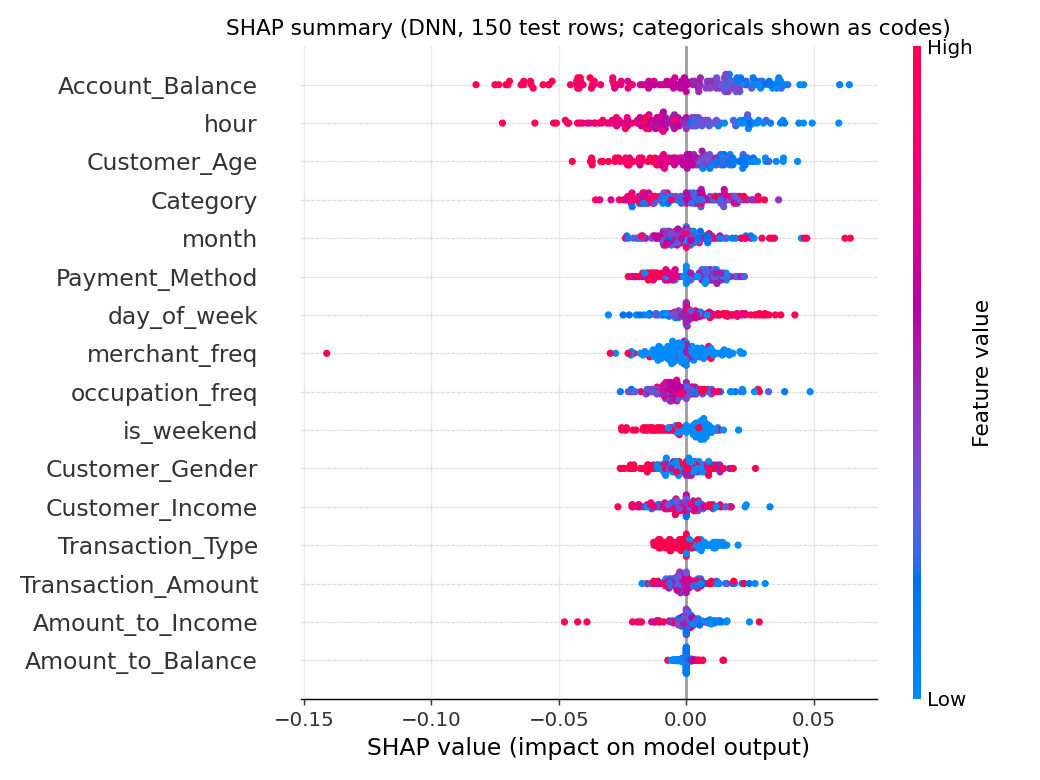

In [7]:
from IPython.display import Image, display
for f in ['roc_curve', 'cost_threshold_analysis', 'shap_summary']: display(Image(str(C.FIGURES_DIR / f'{f}.png')))

**Conclusion:** test ROC-AUC is ≈0.5 for both models. The engineering pipeline works end to end, but the dataset does not contain a learnable fraud signal.